# XGBoost explainability

Explains the tuned XGBoost model from `xgboost.ipynb` with SHAP `TreeExplainer` (exact Shapley values for tree ensembles, one set per class in log-odds space).
Grouped permutation importance is used as a model-agnostic cross-check.

Like the LSTM and GCN explainability notebooks, importance is reported per **base feature** (the 59 features, timesteps collapsed) and per **timestep** (t0-t4).

In [1]:
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import shap
import joblib

from sklearn.preprocessing import label_binarize
from sklearn.metrics import average_precision_score

In [2]:
RANDOM_STATE = 42
DATA_DIR = "../../data/processed"
MODEL_DIR = "../../models"
MODEL_NAME = "xgboost_augmented"
CLASSES = ['Backdoor', 'CommInj', 'DoS', 'Reconn', 'normal']
ATTACK_CLASSES = CLASSES[:-1]
NORMAL_SAMPLE = 2000

# fixed colour per class so every plot uses the same mapping
CLASS_COLORS = dict(zip(CLASSES, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']))

cols = json.load(open(f"{DATA_DIR}/feature_cols.json"))
COLS = cols["numeric"] + cols["categorical"]
N_STEPS = 5

def to_tabular(X):
    return pd.DataFrame(
        X.reshape(X.shape[0], -1),
        columns=[f"t{t}_{c}" for t in range(X.shape[1]) for c in COLS],
    )

X_test = to_tabular(np.load(f"{DATA_DIR}/X_test.npy"))
y_test = np.argmax(np.load(f"{DATA_DIR}/y_test.npy"), axis=1)

model = joblib.load(f"{MODEL_DIR}/{MODEL_NAME}.joblib")
y_pred = model.predict(X_test)

## Explain set

All attack windows in test plus a stratified random sample of normal windows. Explaining all 47k normal windows adds little, since they are almost all classified correctly.

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
normal_id = CLASSES.index('normal')

attack_idx = np.where(y_test != normal_id)[0]
normal_idx = rng.choice(np.where(y_test == normal_id)[0], size=NORMAL_SAMPLE, replace=False)
explain_idx = np.sort(np.concatenate([attack_idx, normal_idx]))

X_explain = X_test.iloc[explain_idx]
y_explain = y_test[explain_idx]
print(pd.Series(y_explain).map(dict(enumerate(CLASSES))).value_counts())

normal      2000
DoS           91
CommInj       51
Backdoor      39
Reconn        31
Name: count, dtype: int64


In [4]:
explainer = shap.TreeExplainer(model)
expl = explainer(X_explain)

# values: (n_samples, n_features, n_classes), in log-odds (margin) space
print(expl.values.shape)

# additivity check: base value + sum of SHAP values must reproduce the raw margin
margin = model.predict(X_explain, output_margin=True)
reconstructed = expl.base_values + expl.values.sum(axis=1)
print("max additivity error:", np.abs(margin - reconstructed).max())

(2212, 295, 5)
max additivity error: 6.198883e-06


## Aggregating to base features and timesteps

Each flattened column is `t{k}_{feature}`. Following the LSTM/GCN notebooks, take |SHAP| first, then sum over timesteps (base feature importance) or over features (timestep importance).

For class `c`, importance is the mean |SHAP| of the class-`c` output over windows whose **true label is `c`**, i.e. what drives detection of that class. The overall score averages the 5 classes equally, so the 2,000 normal windows do not drown out the attacks.

In [5]:
abs_vals = np.abs(expl.values).reshape(len(X_explain), N_STEPS, len(COLS), len(CLASSES))

def per_class_mean(arr):
    # arr: (n_samples, ..., n_classes) -> (..., n_classes), averaged within each true class
    return np.stack(
        [arr[y_explain == c, ..., c].mean(axis=0) for c in range(len(CLASSES))],
        axis=-1,
    )

feat_imp = pd.DataFrame(per_class_mean(abs_vals.sum(axis=1)), index=COLS, columns=CLASSES)
feat_imp['overall'] = feat_imp[CLASSES].mean(axis=1)
feat_imp = feat_imp.sort_values('overall', ascending=False)

time_imp = pd.DataFrame(
    per_class_mean(abs_vals.sum(axis=2)),
    index=[f"t{t}" for t in range(N_STEPS)],
    columns=CLASSES,
)

feat_imp.head(20)

,Backdoor,CommInj,DoS,Reconn,normal,overall
idle_mean,4.845428,1.569565,0.003031,0.092337,1.221644,1.546401
num_dst_ports,0.077209,0.033982,0.000000,3.966422,0.012589,0.818040
dport_registered,0.191301,0.128678,0.000067,1.733687,0.022669,0.415280
src_int_pkt_mean,0.145320,0.059209,1.475561,0.014488,0.226666,0.384249
run_time_sum,0.044293,0.104918,1.619872,0.000000,0.041116,0.362040
mean,0.003093,0.004248,1.755592,0.000000,0.023890,0.357365
tot_load,0.224521,0.491706,0.000000,0.021316,0.971686,0.341846
duration_sum,0.017381,0.140728,1.465207,0.007313,0.038438,0.333813
src_loss,0.656012,0.300228,0.000000,0.502247,0.007608,0.293219
tcp_rtt_mean,0.088516,1.315884,0.000000,0.013151,0.047461,0.293002


## 1. Global feature importance by class

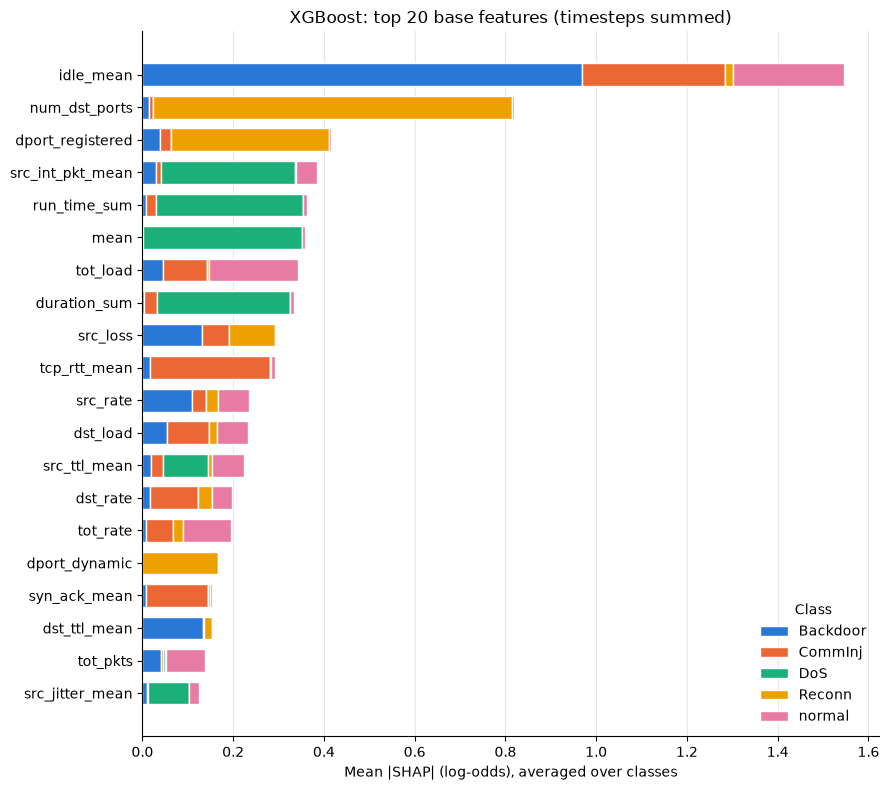

In [6]:
TOP_N = 20
top = feat_imp.head(TOP_N)[CLASSES][::-1] / len(CLASSES)  # stacked segments sum to 'overall'

fig, ax = plt.subplots(figsize=(9, 8))
left = np.zeros(len(top))
for cls in CLASSES:
    ax.barh(top.index, top[cls], left=left, color=CLASS_COLORS[cls],
            edgecolor='white', linewidth=1, label=cls, height=0.7)
    left += top[cls].values

ax.set_xlabel('Mean |SHAP| (log-odds), averaged over classes')
ax.set_title(f'XGBoost: top {TOP_N} base features (timesteps summed)')
ax.legend(title='Class', loc='lower right', frameon=False)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Timestep importance by class

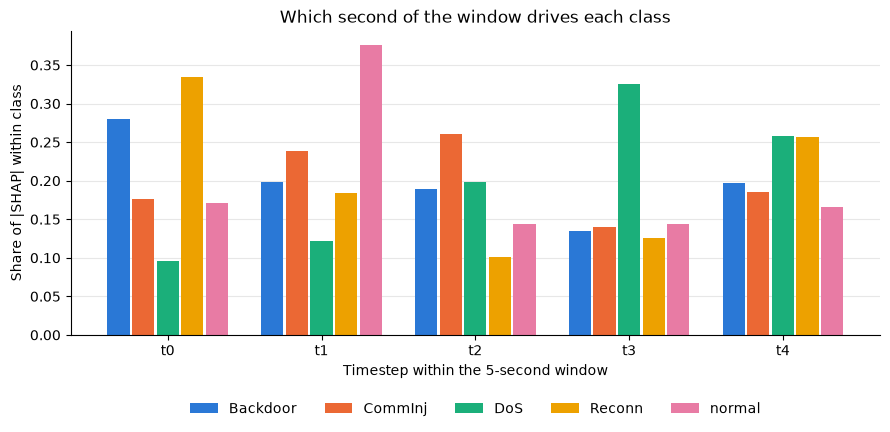

,Backdoor,CommInj,DoS,Reconn,normal
t0,0.279,0.176,0.096,0.334,0.171
t1,0.199,0.238,0.122,0.184,0.375
t2,0.189,0.261,0.199,0.101,0.144
t3,0.135,0.140,0.326,0.125,0.144
t4,0.197,0.185,0.257,0.256,0.166


In [7]:
# normalise within each class so classes with larger margins are comparable
time_share = time_imp / time_imp.sum(axis=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.16
x = np.arange(N_STEPS)
for i, cls in enumerate(CLASSES):
    ax.bar(x + (i - 2) * width, time_share[cls], width=width * 0.9,
           color=CLASS_COLORS[cls], label=cls)

ax.set_xticks(x, time_share.index)
ax.set_xlabel('Timestep within the 5-second window')
ax.set_ylabel('Share of |SHAP| within class')
ax.set_title('Which second of the window drives each class')
ax.legend(ncols=5, loc='upper center', bbox_to_anchor=(0.5, -0.18), frameon=False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

time_share.round(3)

## 3. Beeswarm per attack class

Each dot is one window in the explain set. Position is the SHAP value for that class's output; colour is the (scaled) feature value. Shows the **direction** of each effect, not just its size.

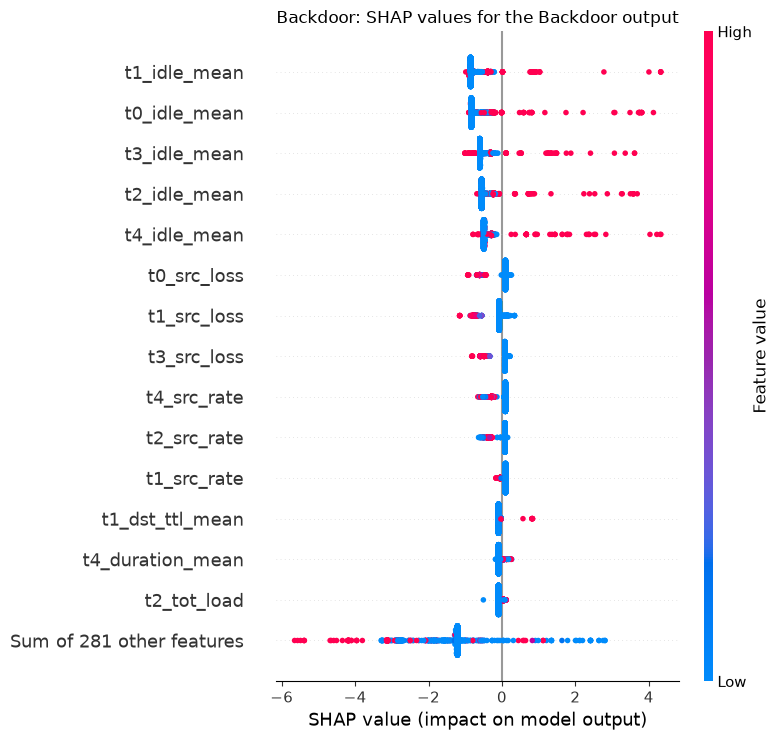

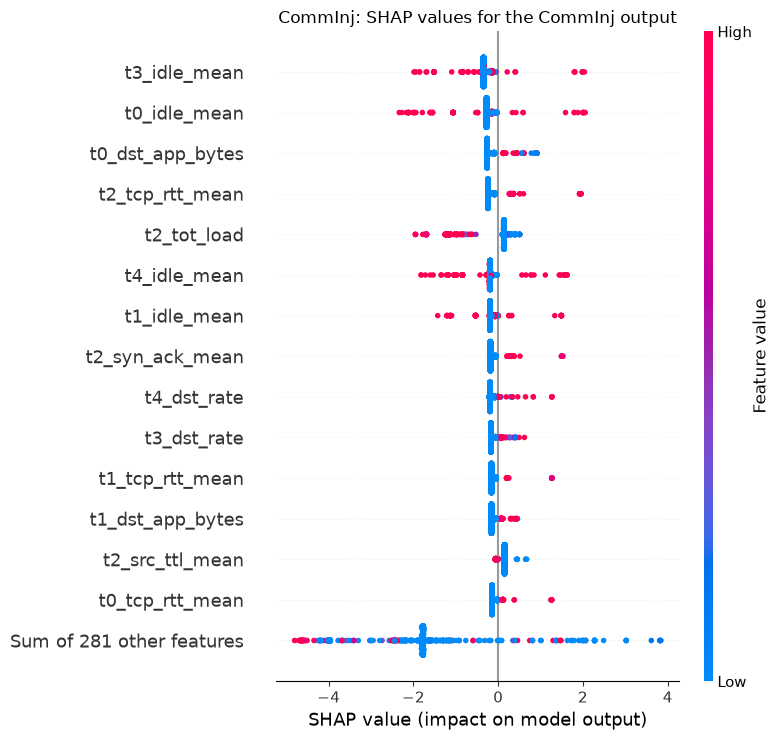

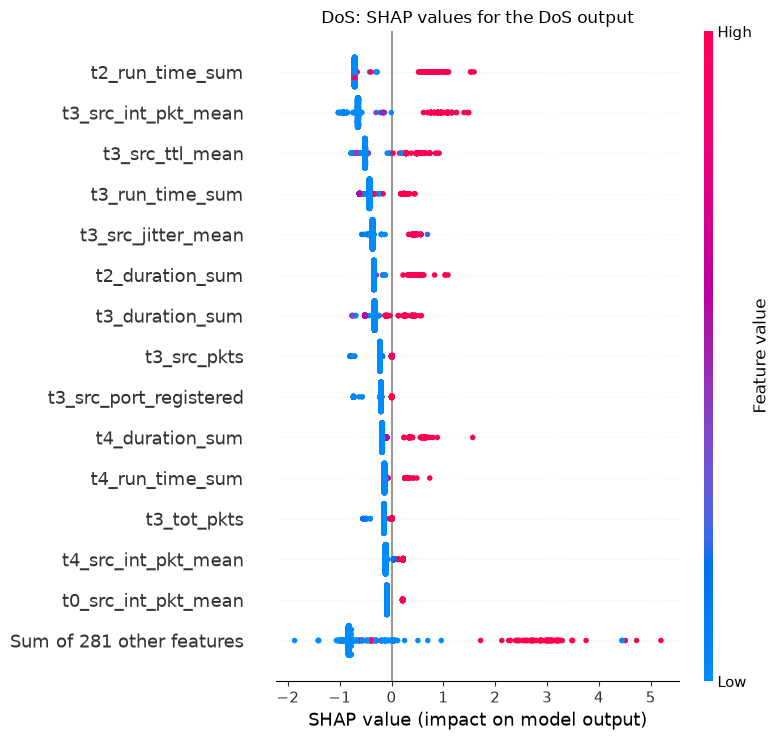

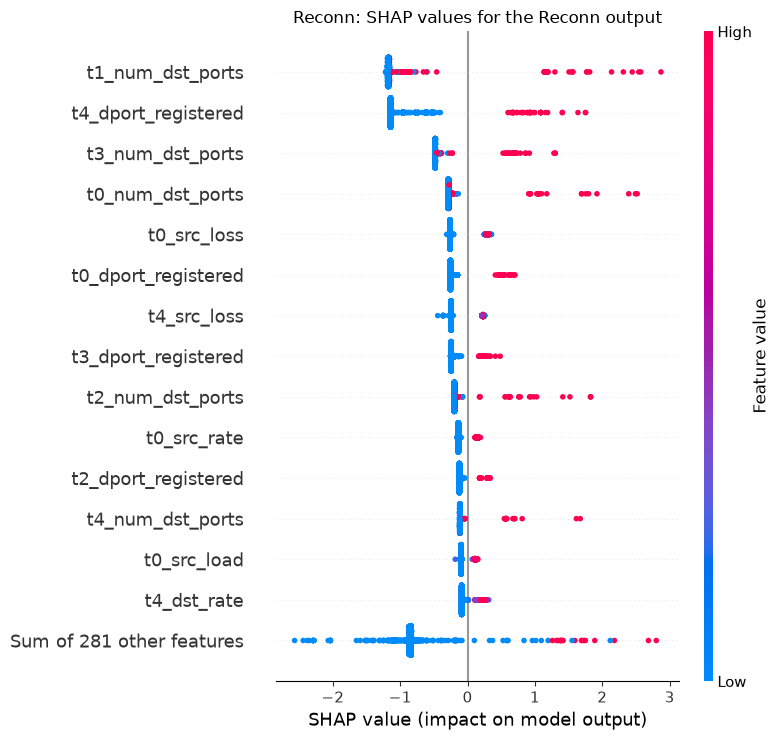

In [8]:
for cls in ATTACK_CLASSES:
    c = CLASSES.index(cls)
    shap.plots.beeswarm(expl[:, :, c], max_display=15, show=False)
    plt.title(f'{cls}: SHAP values for the {cls} output')
    plt.tight_layout()
    plt.show()

## 4. Dependence plots for the top 3 base features

A dependence plot needs a single column, so each base feature uses its highest-ranked timestep column, on the class output where that feature matters most.

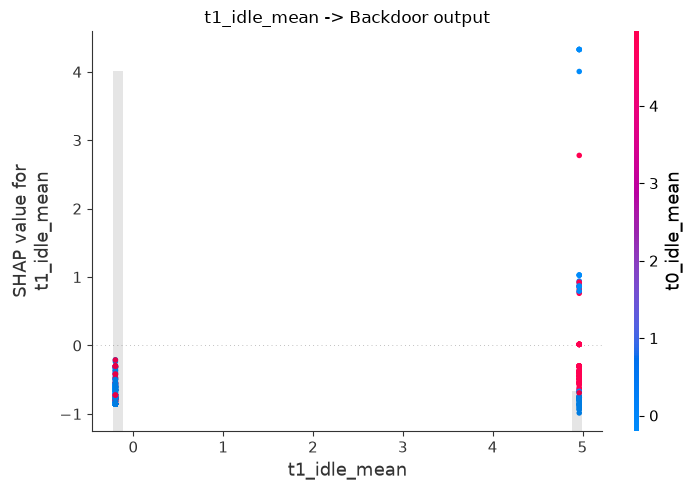

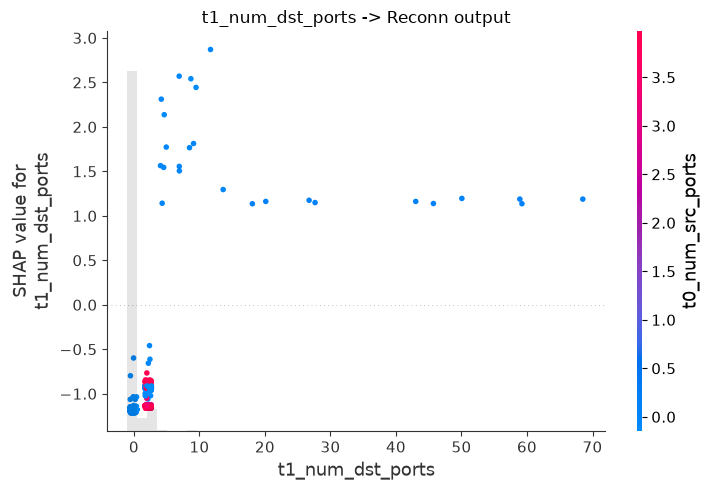

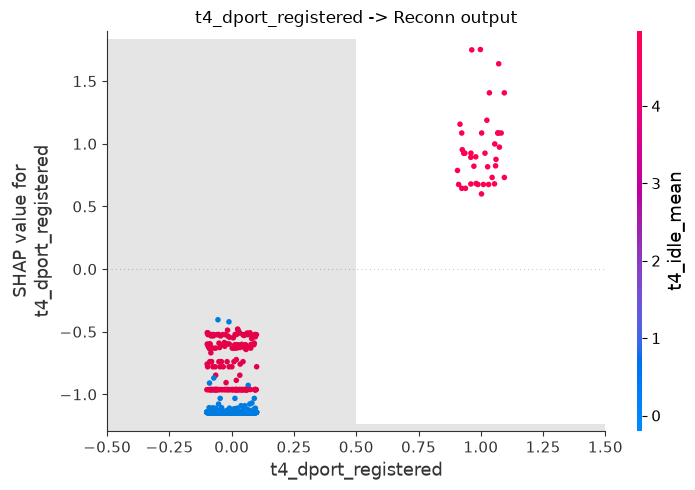

In [9]:
import warnings

col_imp = pd.Series(np.abs(expl.values).mean(axis=(0, 2)), index=X_explain.columns)

for feature in feat_imp.index[:3]:
    column = col_imp[[f"t{t}_{feature}" for t in range(N_STEPS)]].idxmax()
    cls = feat_imp.loc[feature, CLASSES].idxmax()
    c = CLASSES.index(cls)
    # colour picks the strongest interacting column; constant columns trigger a
    # harmless divide-by-zero warning inside its correlation step
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        shap.plots.scatter(expl[:, column, c], color=expl[:, :, c], show=False)
    plt.title(f'{column} -> {cls} output')
    plt.tight_layout()
    plt.show()

## 5. Local explanations (waterfalls)

One correctly classified window per attack class, then up to 5 misclassified test windows. SHAP for the misclassified windows is computed separately because normal-traffic false positives may not be in the sampled explain set.

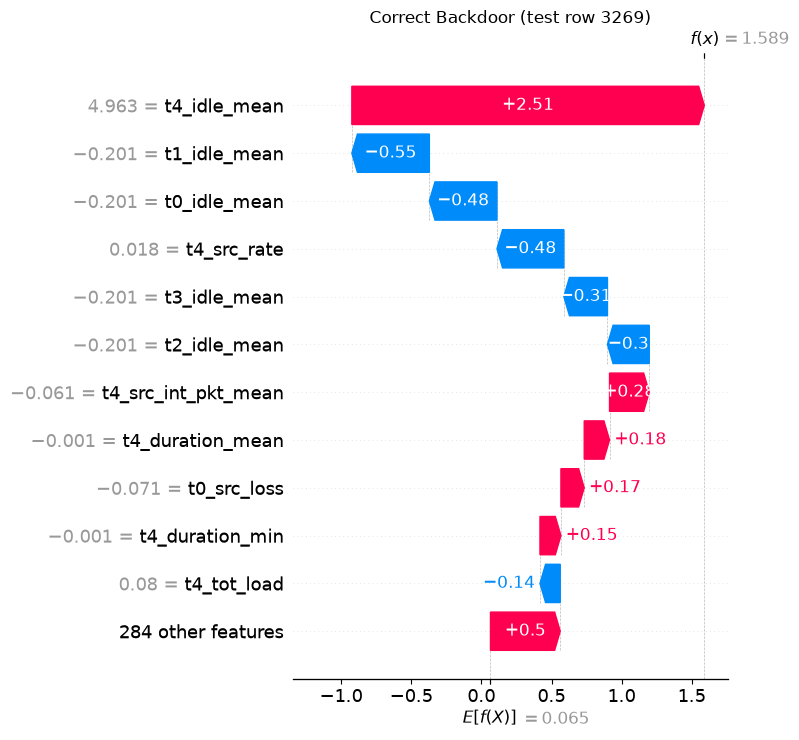

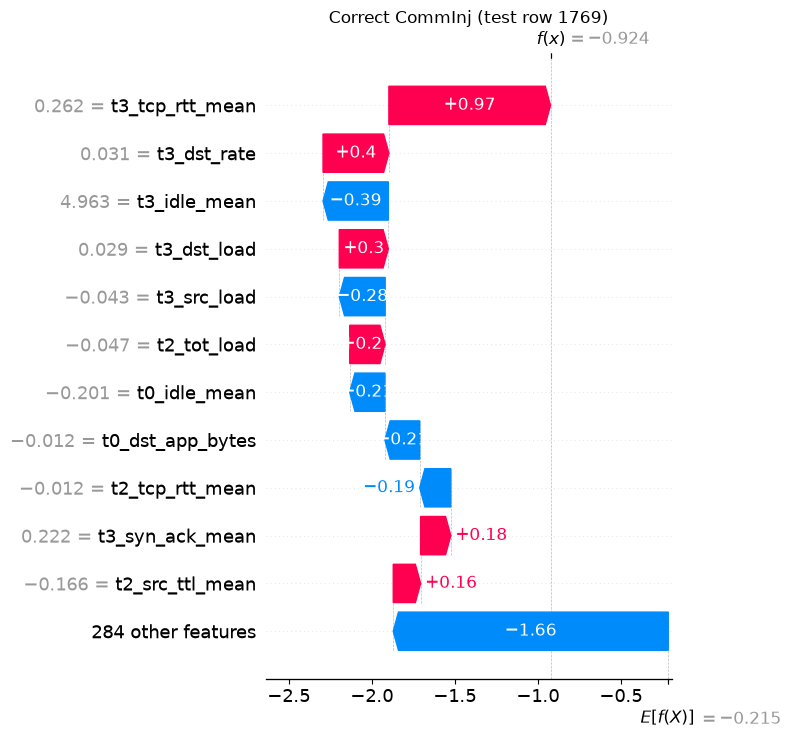

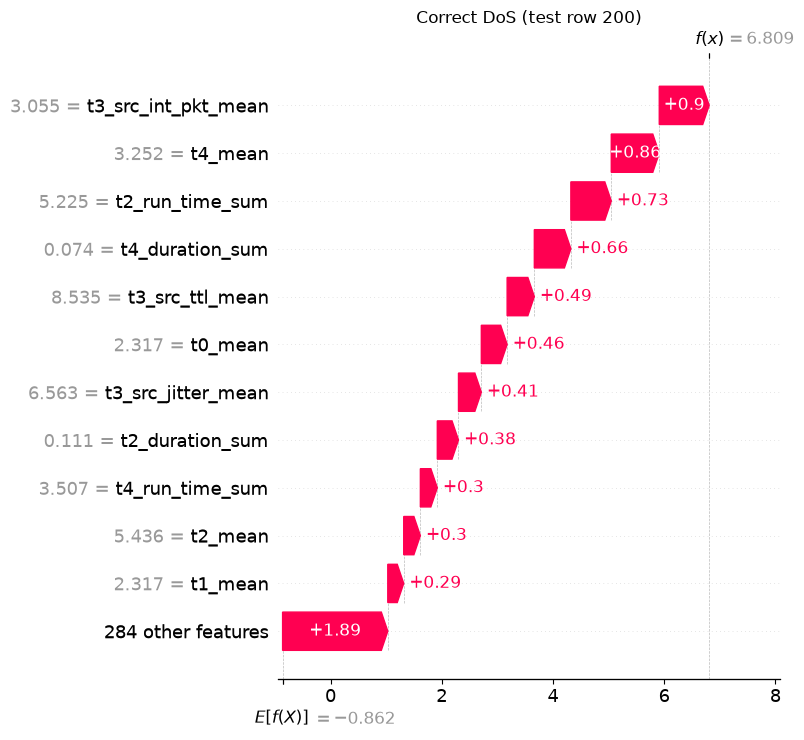

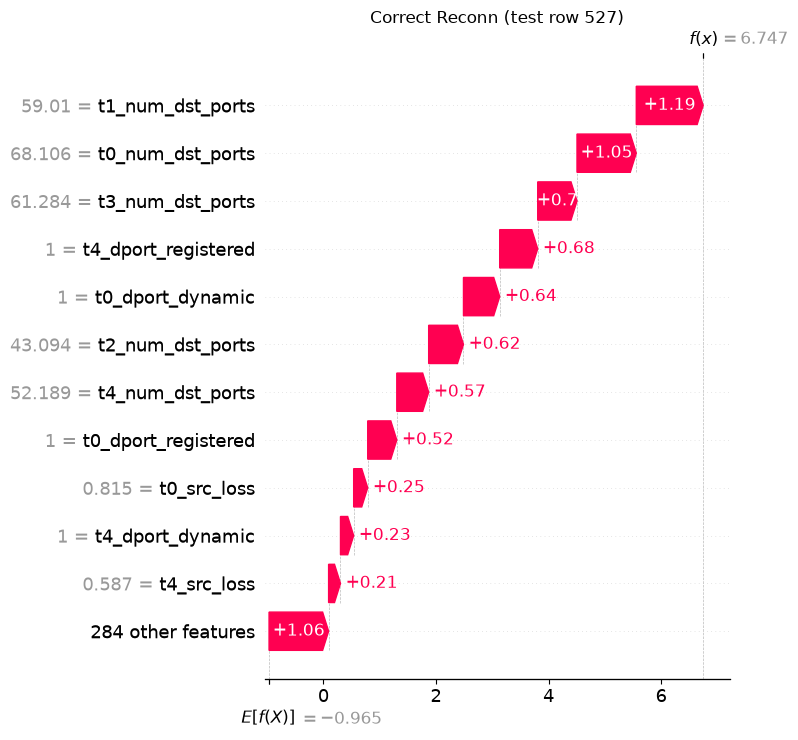

In [10]:
for cls in ATTACK_CLASSES:
    c = CLASSES.index(cls)
    hits = np.where((y_explain == c) & (y_pred[explain_idx] == c))[0]
    if len(hits) == 0:
        print(f'no correctly classified {cls} window')
        continue
    i = hits[0]
    shap.plots.waterfall(expl[i, :, c], max_display=12, show=False)
    plt.title(f'Correct {cls} (test row {explain_idx[i]})')
    plt.tight_layout()
    plt.show()

12 misclassified test windows, showing 5


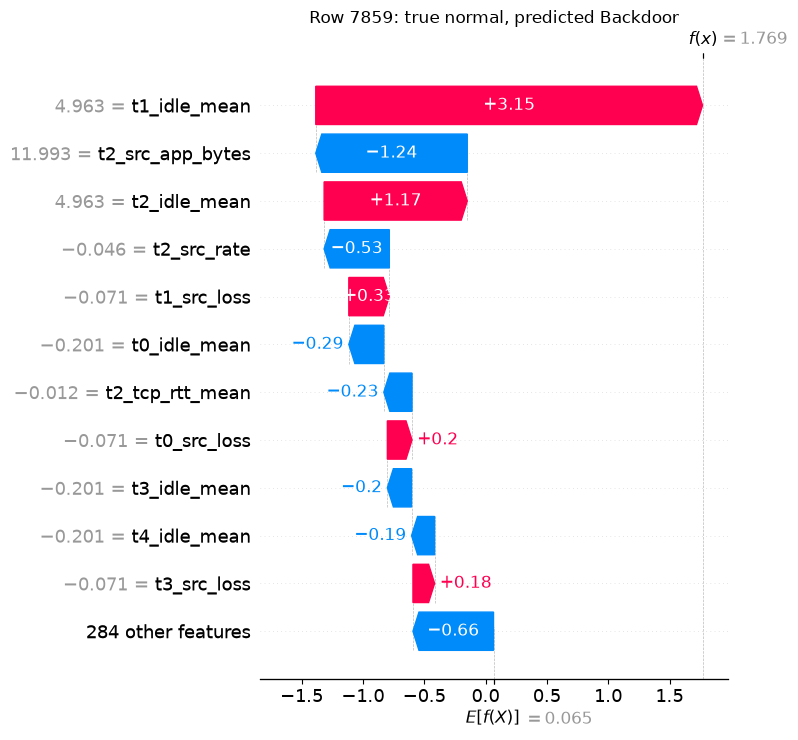

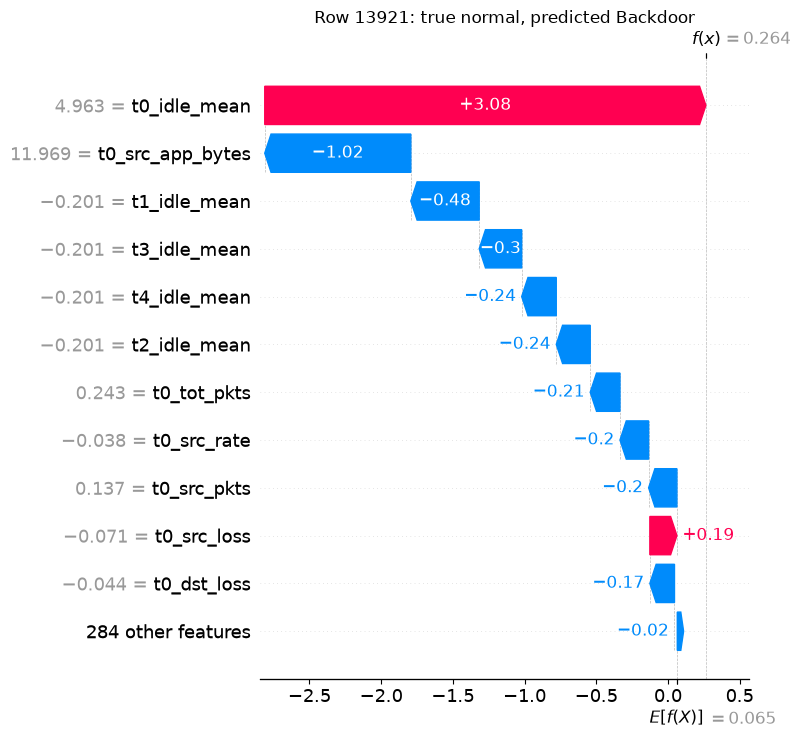

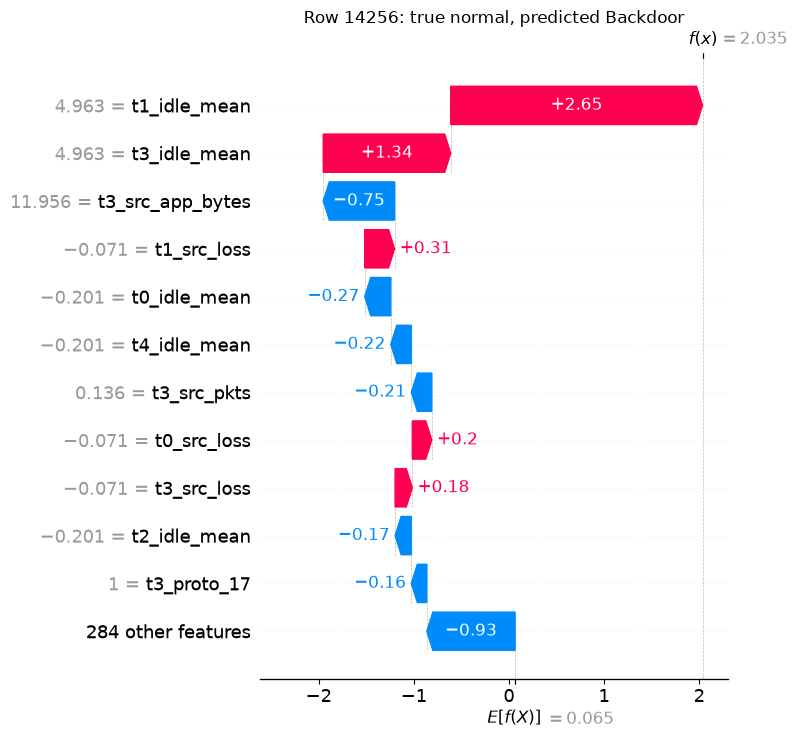

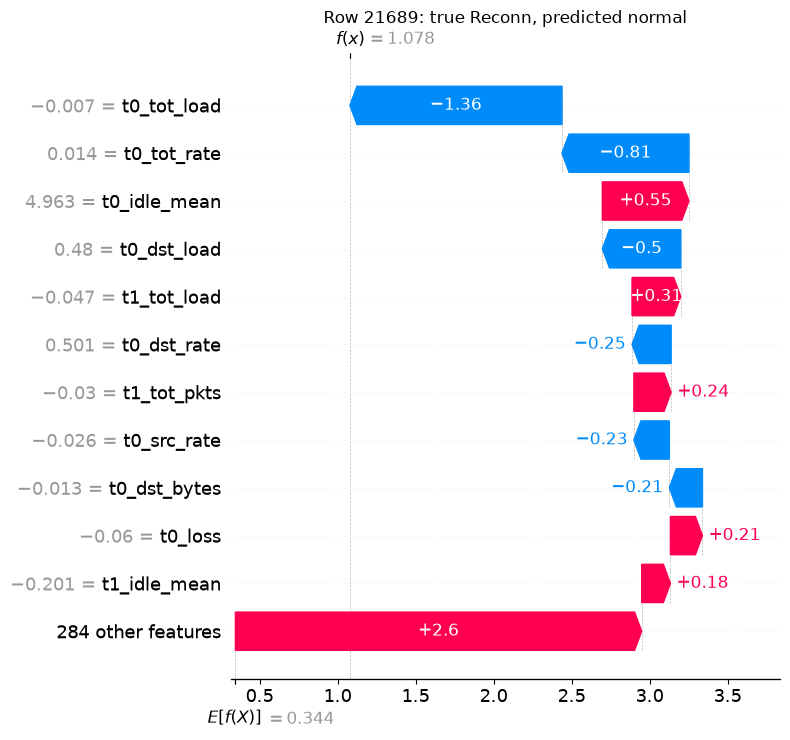

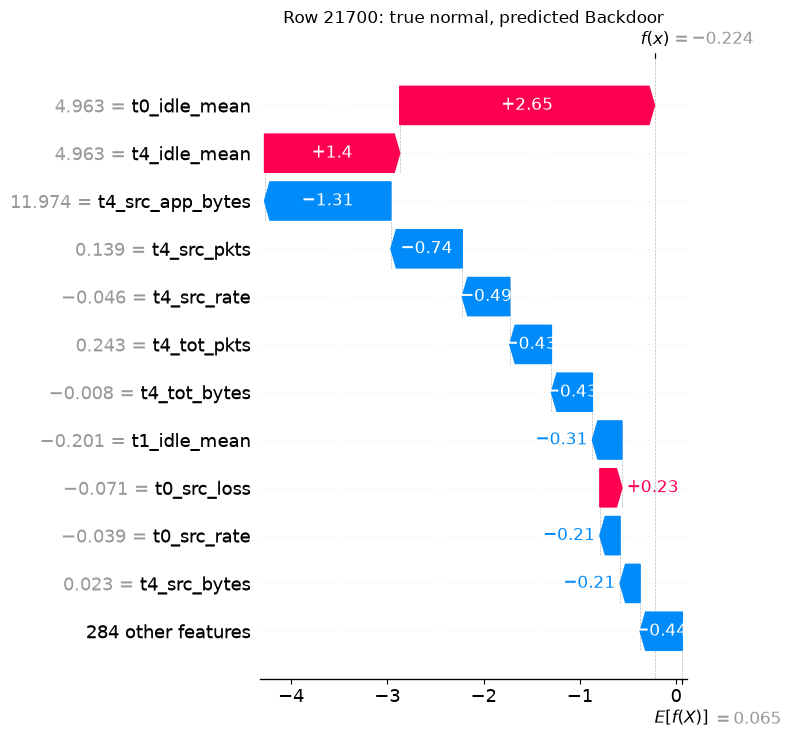

In [11]:
wrong_idx = np.where(y_pred != y_test)[0][:5]
print(f'{(y_pred != y_test).sum()} misclassified test windows, showing {len(wrong_idx)}')

if len(wrong_idx):
    expl_wrong = explainer(X_test.iloc[wrong_idx])
    for j, row in enumerate(wrong_idx):
        true_cls, pred_cls = CLASSES[y_test[row]], CLASSES[y_pred[row]]
        # explain the class the model chose, i.e. why it got this one wrong
        shap.plots.waterfall(expl_wrong[j, :, y_pred[row]], max_display=12, show=False)
        plt.title(f'Row {row}: true {true_cls}, predicted {pred_cls}')
        plt.tight_layout()
        plt.show()

## 6. Grouped permutation importance (cross-check)

Shuffles all 5 timestep columns of a base feature together (same permutation, so each window stays internally consistent) and measures the drop in macro PR-AUC on the full test set. This does not rely on the model's internals, so agreement with the SHAP ranking is a sanity check.

In [12]:
def multiclass_average_precision(y_true, y_proba):
    y_true_binary = label_binarize(y_true, classes=np.arange(len(CLASSES)))
    return average_precision_score(y_true_binary, y_proba, average='macro')

N_REPEATS = 5
base_score = multiclass_average_precision(y_test, model.predict_proba(X_test))
print(f'baseline macro PR-AUC: {base_score:.4f}')

perm_rng = np.random.default_rng(RANDOM_STATE)
drops = {}
X_perm = X_test.copy()
for feature in COLS:
    group = [f"t{t}_{feature}" for t in range(N_STEPS)]
    original = X_test[group].values
    scores = []
    for _ in range(N_REPEATS):
        X_perm[group] = original[perm_rng.permutation(len(X_test))]
        scores.append(base_score - multiclass_average_precision(y_test, model.predict_proba(X_perm)))
    X_perm[group] = original
    drops[feature] = scores

perm_imp = pd.DataFrame({
    'mean_drop': {f: np.mean(s) for f, s in drops.items()},
    'std_drop': {f: np.std(s) for f, s in drops.items()},
}).sort_values('mean_drop', ascending=False)

perm_imp.head(20)

baseline macro PR-AUC: 0.9874


,mean_drop,std_drop
idle_mean,0.183105,0.003083
dst_int_pkt_mean,0.004112,0.000337
dst_load,0.003394,0.000168
tot_load,0.003318,0.000183
src_rate,0.003280,0.000154
dst_pkts,0.003164,0.000029
tot_rate,0.003101,0.000111
src_ttl_mean,0.002483,0.000140
src_app_bytes,0.002199,0.000530
tot_pkts,0.001939,0.000089


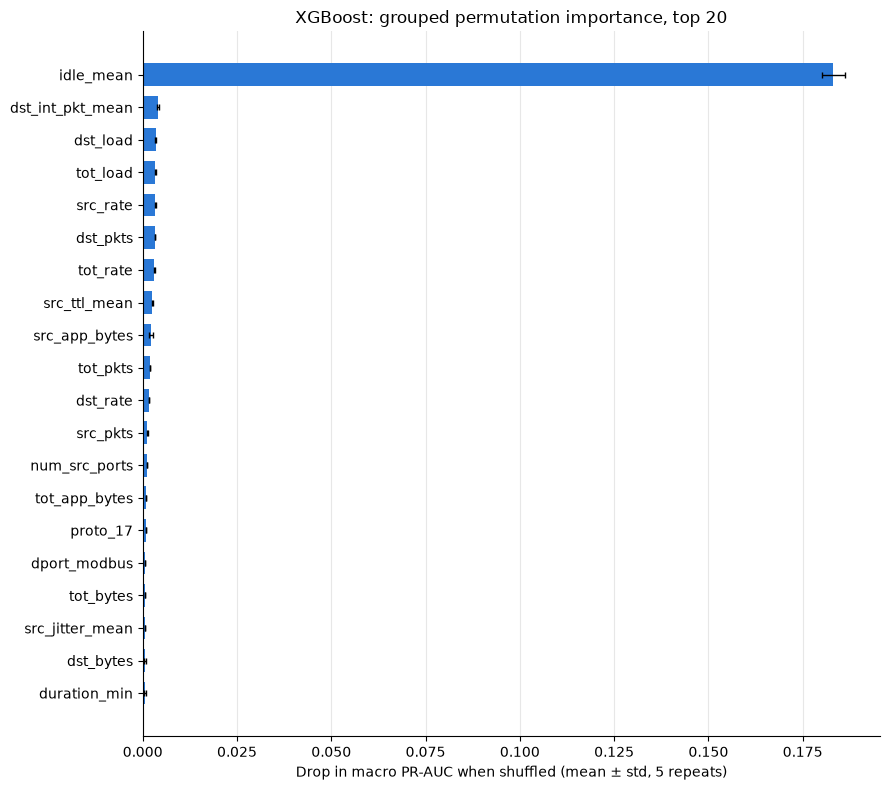

Spearman rank correlation, SHAP vs permutation (all 59 features): 0.398
Top 10 shared: ['idle_mean', 'tot_load']


In [13]:
top_perm = perm_imp.head(TOP_N)[::-1]

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top_perm.index, top_perm['mean_drop'], xerr=top_perm['std_drop'],
        color=CLASS_COLORS['Backdoor'], height=0.7, error_kw={'elinewidth': 1, 'capsize': 2})
ax.set_xlabel(f'Drop in macro PR-AUC when shuffled (mean ± std, {N_REPEATS} repeats)')
ax.set_title(f'XGBoost: grouped permutation importance, top {TOP_N}')
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

shap_rank = feat_imp['overall'].rank(ascending=False)
perm_rank = perm_imp['mean_drop'].rank(ascending=False)
rank_corr = pd.concat([shap_rank, perm_rank], axis=1).corr(method='spearman').iloc[0, 1]
print(f'Spearman rank correlation, SHAP vs permutation (all {len(COLS)} features): {rank_corr:.3f}')
print('Top 10 shared:', sorted(set(feat_imp.index[:10]) & set(perm_imp.index[:10])))

## 7. IP-pair shortcut check

Attacks in this dataset come from only 7 source-destination IP pairs, and those pairs never carry normal traffic. Features that mostly identify the host (TTL, DSCP) rather than the attack's behaviour can therefore act as a label proxy, which would not generalise to new attacker machines.

In [14]:
HOST_FEATURES = ['src_ttl_mean', 'dst_ttl_mean', 'src_dsb_mean']

pd.DataFrame({
    'shap_rank': shap_rank[HOST_FEATURES].astype(int),
    'perm_rank': perm_rank[HOST_FEATURES].astype(int),
    'share_of_total_shap': (feat_imp.loc[HOST_FEATURES, 'overall'] / feat_imp['overall'].sum()).round(3),
})

,shap_rank,perm_rank,share_of_total_shap
src_ttl_mean,13,8,0.027
dst_ttl_mean,18,54,0.019
src_dsb_mean,46,43,0.000


### `idle_mean` is a timestamp leak

`idle_mean` dominates both SHAP and permutation importance. In the raw CSV, `IdleTime` is not an idle duration but a **Unix timestamp** (~1.5488e9, i.e. 30 Jan 2019), and each attack type was recorded in its own time block. So after scaling, the value of a non-empty second encodes *when* it was captured, and the trees split on differences in the 4th decimal place to tell attack types apart.

In [15]:
trees = model.get_booster().trees_to_dataframe()
idle_splits = trees[trees.Feature.str.contains('idle_mean', na=False)]
print(f"splits on idle_mean: {len(idle_splits)} of {(trees.Feature != 'Leaf').sum()}")
print(idle_splits.Split.round(4).value_counts())

# value range of idle_mean in non-empty seconds (empty seconds are zero-filled before scaling)
idle_cols = [f"t{t}_idle_mean" for t in range(N_STEPS)]
for c, cls in enumerate(CLASSES):
    v = X_test.loc[y_test == c, idle_cols].values.ravel()
    v = v[v > 1]
    print(f"{cls:9s} {v.min():.4f} - {v.max():.4f}")

splits on idle_mean: 1139 of 6403
Split
4.9632    582
4.9631    404
4.9628    152
4.9629      1
Name: count, dtype: int64
Backdoor  4.9631 - 4.9632
CommInj   4.9631 - 4.9631
DoS       4.9628 - 4.9628
Reconn    4.9628 - 4.9628
normal    4.9628 - 4.9632


**Implication:** part of the reported performance comes from recording time, not traffic behaviour. Since every model here uses the same 59 features, the LSTM, CNN and GCN results are likely affected too. Dropping `idle_mean` in preprocessing (or converting it to a real duration, if that was intended) and retraining would give an honest number.

## 8. Export

In [16]:
out = feat_imp.rename(columns={c: f'shap_{c}' for c in CLASSES + ['overall']})
out = out.join(perm_imp)
out.index.name = 'feature'
out.to_csv(f'{MODEL_DIR}/xgboost_feature_importance.csv')
out.head()

,shap_Backdoor,shap_CommInj,shap_DoS,shap_Reconn,shap_normal,shap_overall,mean_drop,std_drop
feature,,,,,,,,
idle_mean,4.845428,1.569565,0.003031,0.092337,1.221644,1.546401,0.183105,0.003083
num_dst_ports,0.077209,0.033982,0.000000,3.966422,0.012589,0.818040,0.000418,0.000073
dport_registered,0.191301,0.128678,0.000067,1.733687,0.022669,0.415280,0.000197,0.000044
src_int_pkt_mean,0.145320,0.059209,1.475561,0.014488,0.226666,0.384249,0.000168,0.000163
run_time_sum,0.044293,0.104918,1.619872,0.000000,0.041116,0.362040,-0.000286,0.000074
